# Şehrin Nabzı Saatlik Bisiklet Paylaşım Talebi Tahmini

Bu çalışma, Washington D.C. Capital Bikeshare sistemindeki saatlik yolculuk başlangıcı sayısını takvim ve hava koşullarından tahmin eder.

**Veri dönemi:** 1 Ocak-31 Aralık 2025  
**Kaynak kapsamı:** 6.662.611 yolculuk, 8.760 saat  
**Problem türü:** Regresyon  
**Hedef:** `kiralama_sayisi`

Kaynaklar: [Capital Bikeshare System Data](https://capitalbikeshare.com/system-data) ve [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api).

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)

/Users/serratanis/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/7p/7hglmwtd48d84m9fb6n55grr0000gn/T/matplotlib-jerz2raj because there was an issue with the default path (/Users/serratanis/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


## 1 Veri dosyasını okuma

Yerel proje klasöründe CSV otomatik bulunur. Not defteri Colab'a tek başına yüklendiğinde dosya seçme ekranı açılır.

In [2]:
candidates = [
    Path("data/processed/sehrin_nabzi_bisiklet_talebi.csv"),
    Path("../data/processed/sehrin_nabzi_bisiklet_talebi.csv"),
    Path("sehrin_nabzi_bisiklet_talebi.csv"),
]
DATA_PATH = next((path for path in candidates if path.exists()), None)
if DATA_PATH is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = Path(next(iter(uploaded)))
    except Exception as exc:
        raise FileNotFoundError("sehrin_nabzi_bisiklet_talebi.csv dosyasını ekleyin.") from exc

df = pd.read_csv(DATA_PATH, parse_dates=["tarih_saat"])
print(f"Dosya: {DATA_PATH}")
print(f"Boyut: {df.shape[0]} satır x {df.shape[1]} sütun")
df.head()

Dosya: data/processed/sehrin_nabzi_bisiklet_talebi.csv
Boyut: 8760 satır x 15 sütun


,tarih_saat,tarih,yil,mevsim,ay,saat,tatil,hafta_gunu,is_gunu,hava_durumu,sicaklik_c,nem_yuzde,ruzgar_kmh,yagis_mm,kiralama_sayisi
0,2025-01-01 00:00:00,2025-01-01,2025,4,1,0,1,2,0,1,8.2,92.0,11.7,0.0,431
1,2025-01-01 01:00:00,2025-01-01,2025,4,1,1,1,2,0,1,8.0,91.0,13.0,0.0,513
2,2025-01-01 02:00:00,2025-01-01,2025,4,1,2,1,2,0,1,8.0,85.0,13.6,0.0,368
3,2025-01-01 03:00:00,2025-01-01,2025,4,1,3,1,2,0,1,7.4,86.0,14.3,0.0,161
4,2025-01-01 04:00:00,2025-01-01,2025,4,1,4,1,2,0,1,7.1,82.0,15.2,0.0,88


## 2 Veri kalitesi ve özet istatistikler

In [3]:
print("Eksik değer toplamı:", int(df.isna().sum().sum()))
print("Tekrarlanan saat:", int(df["tarih_saat"].duplicated().sum()))
print("Kaynak yolculuk toplamı:", f"{df['kiralama_sayisi'].sum():,}")
display(df.dtypes.to_frame("tip"))
df.describe().T

Eksik değer toplamı: 0
Tekrarlanan saat: 0
Kaynak yolculuk toplamı: 6,662,611


,tip
tarih_saat,datetime64[ns]
tarih,object
yil,int64
mevsim,int64
ay,int64
saat,int64
tatil,int64
hafta_gunu,int64
is_gunu,int64
hava_durumu,int64


,count,mean,min,25%,50%,75%,max,std
tarih_saat,8760,2025-07-02 11:30:00,2025-01-01 00:00:00,2025-04-02 05:45:00,2025-07-02 11:30:00,2025-10-01 17:15:00,2025-12-31 23:00:00,NaN
yil,8760.0,2025.0,2025.0,2025.0,2025.0,2025.0,2025.0,0.0
mevsim,8760.0,2.490411,1.0,1.0,2.0,3.0,4.0,1.116831
ay,8760.0,6.526027,1.0,4.0,7.0,10.0,12.0,3.448048
saat,8760.0,11.5,0.0,5.75,11.5,17.25,23.0,6.922582
tatil,8760.0,0.030137,0.0,0.0,0.0,0.0,1.0,0.170974
hafta_gunu,8760.0,2.99726,0.0,1.0,3.0,5.0,6.0,1.998056
is_gunu,8760.0,0.684932,0.0,0.0,1.0,1.0,1.0,0.46457
hava_durumu,8760.0,1.642123,1.0,1.0,1.0,2.0,3.0,0.721457
sicaklik_c,8760.0,13.73653,-14.5,5.5,14.9,22.2,39.7,10.359015


## 3 Grup karşılaştırmaları

`groupby` saat ve hava sınıflarındaki ortalama talebi, `value_counts` ise hava sınıflarının sıklığını gösterir.

In [4]:
saat_ozeti = df.groupby("saat")["kiralama_sayisi"].agg(["count", "mean", "median", "max"])
hava_ozeti = df.groupby("hava_durumu")["kiralama_sayisi"].agg(["count", "mean", "median"])
hava_sayilari = df["hava_durumu"].value_counts().sort_index()

display(saat_ozeti.round(1))
display(hava_ozeti.round(1))
display(hava_sayilari.to_frame("gözlem"))

,count,mean,median,max
saat,,,,
0,365,218.1,159.0,719
1,365,127.4,76.0,642
2,365,77.9,44.0,574
3,365,43.4,27.0,286
4,365,44.7,43.0,127
5,365,123.6,127.0,243
6,365,316.9,334.0,652
7,365,690.4,753.0,1336
8,365,1135.2,1261.0,2167


,count,mean,median
hava_durumu,,,
1,4408,771.6,660.5
2,3079,758.0,650.0
3,1273,728.7,580.0


,gözlem
hava_durumu,
1,4408
2,3079
3,1273


## 4 Keşifçi veri analizi

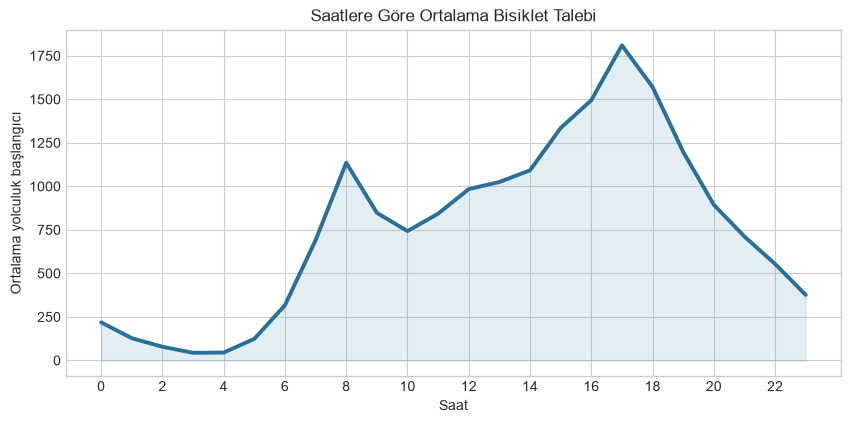

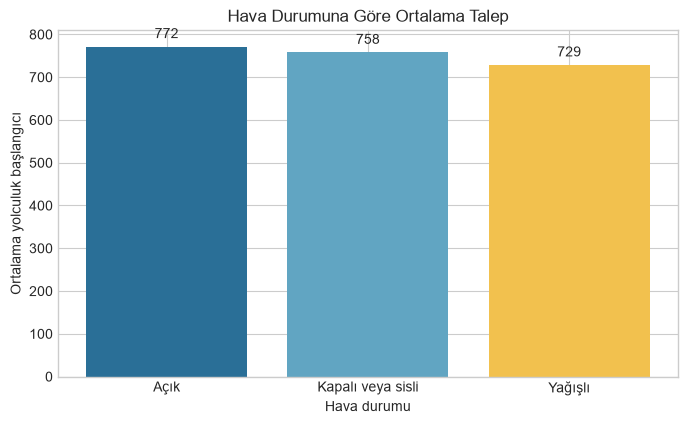

In [5]:
hourly = df.groupby("saat")["kiralama_sayisi"].mean()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(hourly.index, hourly.values, color="#2A6F97", linewidth=2.8)
ax.fill_between(hourly.index, hourly.values, color="#61A5C2", alpha=0.18)
ax.set(title="Saatlere Göre Ortalama Bisiklet Talebi",
       xlabel="Saat", ylabel="Ortalama yolculuk başlangıcı")
ax.set_xticks(range(0, 24, 2))
plt.show()

labels = {1: "Açık", 2: "Kapalı veya sisli", 3: "Yağışlı", 4: "Gök gürültülü"}
weather = df.groupby("hava_durumu")["kiralama_sayisi"].mean()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([labels[i] for i in weather.index], weather.values,
              color=["#2A6F97", "#61A5C2", "#F2C14E", "#D95D39"][:len(weather)])
ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set(title="Hava Durumuna Göre Ortalama Talep",
       xlabel="Hava durumu", ylabel="Ortalama yolculuk başlangıcı")
plt.show()

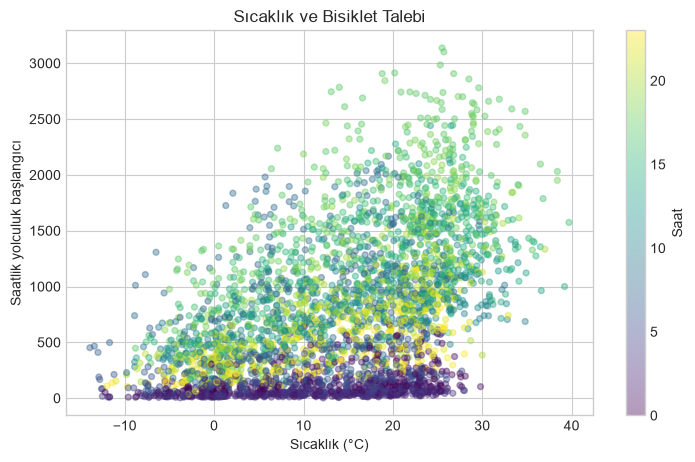

,sicaklik_c,nem_yuzde,ruzgar_kmh,yagis_mm,kiralama_sayisi
sicaklik_c,1.000,0.010,-0.208,0.054,0.478
nem_yuzde,0.010,1.000,-0.261,0.237,-0.426
ruzgar_kmh,-0.208,-0.261,1.000,0.032,-0.015
yagis_mm,0.054,0.237,0.032,1.000,-0.036
kiralama_sayisi,0.478,-0.426,-0.015,-0.036,1.000


In [6]:
sample = df.sample(n=3500, random_state=42)
fig, ax = plt.subplots(figsize=(8.5, 5))
scatter = ax.scatter(sample["sicaklik_c"], sample["kiralama_sayisi"],
                     c=sample["saat"], cmap="viridis", alpha=0.4, s=18)
fig.colorbar(scatter, ax=ax, label="Saat")
ax.set(title="Sıcaklık ve Bisiklet Talebi",
       xlabel="Sıcaklık (°C)", ylabel="Saatlik yolculuk başlangıcı")
plt.show()

df[["sicaklik_c", "nem_yuzde", "ruzgar_kmh", "yagis_mm", "kiralama_sayisi"]].corr().round(3)

### Keşif bulguları

1. Ortalama talep saat 17.00'de 1.810 yolculukla zirveye çıkıyor.
2. Haziran ayı saatlik ortalaması 960 ile yılın en yüksek aylık düzeyine ulaşıyor.
3. Sıcaklık ile talep arasında 0,478 düzeyinde pozitif ilişki var.
4. Nem yükseldikçe talep genel olarak azalıyor; korelasyon -0,426.
5. Rüzgâr hızı tek başına talebi açıklamakta zayıf kalıyor.

## 5 Model kurulumu

In [7]:
TARGET = "kiralama_sayisi"
CATEGORICAL_FEATURES = [
    "mevsim", "ay", "saat", "tatil", "hafta_gunu", "is_gunu", "hava_durumu"
]
NUMERIC_FEATURES = ["sicaklik_c", "nem_yuzde", "ruzgar_kmh", "yagis_mm"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, shuffle=False
)
print("Eğitim boyutu:", X_train.shape, y_train.shape)
print("Test boyutu:", X_test.shape, y_test.shape)
print("Test dönemi:", df.loc[X_test.index, "tarih_saat"].min().date(),
      "-", df.loc[X_test.index, "tarih_saat"].max().date())

preprocessor = ColumnTransformer([
    ("kategorik", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ("sayisal", StandardScaler(), NUMERIC_FEATURES),
])
model = Pipeline([
    ("on_isleme", preprocessor),
    ("model", LinearRegression()),
])
model.fit(X_train, y_train)
print("Model eğitildi.")

Eğitim boyutu: (7008, 11) (7008,)
Test boyutu: (1752, 11) (1752,)
Test dönemi: 2025-10-20 - 2025-12-31
Model eğitildi.


### Model seçim gerekçesi

Linear Regression, hedef değişken sayısal olduğu için probleme uygundur. Model eğitim yönergesindeki temel regresyon yöntemini gösterir ve sonucu kolay açıklanır. Kategorik alanların one-hot encoding ile dönüştürülmesi, saat veya mevsim kodlarının yapay bir doğrusal sıra gibi ele alınmasını önler.

## 6 Tahmin ve değerlendirme

In [8]:
predictions = model.predict(X_test)
baseline = np.full(len(y_test), y_train.mean())
metrics = pd.Series({
    "R²": r2_score(y_test, predictions),
    "MAE": mean_absolute_error(y_test, predictions),
    "RMSE": mean_squared_error(y_test, predictions) ** 0.5,
    "Temel yaklaşım MAE": mean_absolute_error(y_test, baseline),
})
metrics.round(3).to_frame("değer")

,değer
R²,0.578
MAE,234.295
RMSE,315.201
Temel yaklaşım MAE,476.801


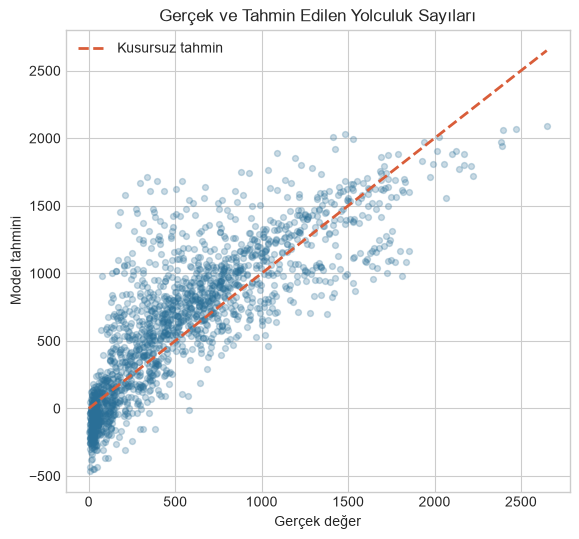

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test, predictions, alpha=0.25, s=18, color="#2A6F97")
maximum = max(float(y_test.max()), float(predictions.max()))
ax.plot([0, maximum], [0, maximum], "--", color="#D95D39", linewidth=2,
        label="Kusursuz tahmin")
ax.set(title="Gerçek ve Tahmin Edilen Yolculuk Sayıları",
       xlabel="Gerçek değer", ylabel="Model tahmini")
ax.legend(frameon=False)
plt.show()

## 7 Yeni örnekler için tahmin

In [10]:
def tahmin_et(model, **values):
    frame = pd.DataFrame([values], columns=FEATURES)
    return int(round(max(0.0, float(model.predict(frame)[0]))))

new_examples = pd.DataFrame([
    {"senaryo": "Serin iş günü sabahı", "mevsim": 1, "ay": 4, "saat": 8,
     "tatil": 0, "hafta_gunu": 1, "is_gunu": 1, "hava_durumu": 1,
     "sicaklik_c": 14.0, "nem_yuzde": 58.0, "ruzgar_kmh": 11.0, "yagis_mm": 0.0},
    {"senaryo": "Sıcak hafta sonu öğleden sonrası", "mevsim": 2, "ay": 7, "saat": 16,
     "tatil": 0, "hafta_gunu": 5, "is_gunu": 0, "hava_durumu": 1,
     "sicaklik_c": 31.0, "nem_yuzde": 48.0, "ruzgar_kmh": 9.0, "yagis_mm": 0.0},
    {"senaryo": "Yağışlı kış gecesi", "mevsim": 4, "ay": 12, "saat": 23,
     "tatil": 0, "hafta_gunu": 2, "is_gunu": 1, "hava_durumu": 3,
     "sicaklik_c": 5.0, "nem_yuzde": 86.0, "ruzgar_kmh": 20.0, "yagis_mm": 2.0},
])
new_examples["tahmin"] = [
    tahmin_et(model, **row[FEATURES].to_dict())
    for _, row in new_examples.iterrows()
]
new_examples[["senaryo", "tahmin"]]

,senaryo,tahmin
0,Serin iş günü sabahı,1413
1,Sıcak hafta sonu öğleden sonrası,1858
2,Yağışlı kış gecesi,0


In [11]:
def tahmini_yorumla(value):
    if value < 250:
        level = "düşük"
    elif value < 700:
        level = "orta"
    else:
        level = "yüksek"
    return f"Yaklaşık {value} yolculuk başlangıcı bekleniyor. Talep düzeyi {level}."

for _, row in new_examples.iterrows():
    print(f"{row['senaryo']}: {tahmini_yorumla(int(row['tahmin']))}")

Serin iş günü sabahı: Yaklaşık 1413 yolculuk başlangıcı bekleniyor. Talep düzeyi yüksek.
Sıcak hafta sonu öğleden sonrası: Yaklaşık 1858 yolculuk başlangıcı bekleniyor. Talep düzeyi yüksek.
Yağışlı kış gecesi: Yaklaşık 0 yolculuk başlangıcı bekleniyor. Talep düzeyi düşük.


## 8 Değerlendirme notu

Model, ileri tarihli test döneminde talep değişiminin yaklaşık yüzde 58'ini açıklıyor. Ortalama mutlak hata 234,3 yolculuk; eğitim ortalamasına dayalı temel yaklaşımın hatası 476,8. Model temel yaklaşımın hatasını yüzde 50,9 azaltıyor.

Model istasyon kapasitesi, özel etkinlik ve toplu taşıma kesintisi bilgilerini kullanmıyor. Veri yalnızca Washington D.C. ve 2025 dönemini temsil ediyor. Gelecek sürümde bu değişkenler eklenebilir ve doğrusal model bir ağaç tabanlı yöntemle aynı ileri tarihli test döneminde karşılaştırılabilir.